## Speed modulations

Analyzes speed modulations during continuous swimming using signal autocorrelation (ACF).

Produces ACF plots for two fish examples. 

Figures are saved to the project `figures/` directory and to `speed_modulations/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
print(os.getcwd()) 

<repo>/code/speed_modulations


In [3]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("speed_modulations"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


In [4]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

#### Import data:

In [5]:
factor_thrust = 0.35 #microN

In [6]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [7]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [8]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
#fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20, 21]


In [9]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [10]:
#SORTING BY ETA
index_cont = [0, 1, 2, 8]
index_mix = [3, 4, 5, 6, 7, 9, 11, 12, 13, 14, 17]
index_bout = [10, 15, 16, 18, 19]

In [11]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [12]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 27, 28, 30, 34, 34]


Load:

In [13]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [14]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [16]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [17]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [18]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [19]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:02<01:02,  2.98s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:05<00:57,  2.87s/it]

...

 91%|█████████ | 20/22 [00:57<00:05,  2.88s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [00:59<00:02,  2.82s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:02<00:00,  2.85s/it]


In [20]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:02<01:01,  2.93s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:05<00:55,  2.78s/it]

...

 91%|█████████ | 20/22 [00:55<00:05,  2.75s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [00:57<00:02,  2.72s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:00<00:00,  2.75s/it]


In [21]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 22/22 [00:00<00:00, 163.52it/s]

Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


## Speed modulation - continuous 

In [22]:


i=6



In [23]:


dt=1/300
t_before=0.1
t_after=3
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,mean_thrust_c_list[i][indices]*5000,'k-',alpha=1)
    ax.axvline(bout_duration_list[i][n],color='gray')
    ax.set_xlim(-t_before,t_after)

    plt.show()



interactive(children=(IntSlider(value=0, description='n', max=2446), Output()), _dom_classes=('widget-interact…

In [24]:
from functions.MC_freely_swimming import *
th_cont = 3 #s
dt=1/300
t_before=0.1

t_cont_onset_list = []
t_cont_after_list = []
t_cont_list = []
vtail_cont_list = []
vfish_cont_list = []
mean_thrust_cont_list = []

tmax_cont_list, vmax_cont_list = [], []

for i in range(len(fish_ids)):
    print(str(i) + '-processing ' + str(fish_ids[i]))
    t_cont_onset = []
    t_cont = []
    vtail_cont = []
    vfish_cont = []
    mean_thrust_cont = []
    t_cont_after = []
    tmax_fish, vmax_fish = [], []
    for n in range(len(bout_duration_list[i])):
        if bout_duration_list[i][n] > th_cont: # only continuous sequences
            t_onset = t_c_list[i][onset_indices_list[i][n]]
            indices = (t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+bout_duration_list[i][n])
            #indices = (t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+1) #consoder only 1s after onset
            tmax, vmax = extract_first_peak_times_and_values_single_onset(vfish_c_list[i][indices], t_c_list[i][indices], sigma=10)
 
            t_cont_onset.append(t_onset)
            t_cont_after.append(bout_duration_list[i][n])
            t_cont.append(t_c_list[i][indices])
            vtail_cont.append(vtail_c_list[i][indices])
            vfish_cont.append(vfish_c_list[i][indices])
            mean_thrust_cont.append(mean_thrust_c_list[i][indices])
            
            tmax_fish.append(tmax)
            vmax_fish.append(vmax)
        
    
    t_cont_onset_list.append(t_cont_onset)
    t_cont_after_list.append(t_cont_after)
    t_cont_list.append(t_cont)
    vtail_cont_list.append(vtail_cont)
    vfish_cont_list.append(vfish_cont)
    mean_thrust_cont_list.append(mean_thrust_cont)
    tmax_cont_list.append(tmax_fish)
    vmax_cont_list .append(vmax_fish)

0-processing 13_06May24_1
1-processing 13_30Oct24_3
2-processing 13_30Oct24_4
3-processing 14_27Mar24_1
4-processing 14_31Oct24_1
5-processing 17_21May24_2
6-processing 18_22May24_1
7-processing 18_22May24_2
8-processing 19_23May24_5
9-processing 20_05Jun24_1
10-processing 20_05Jun24_2
11-processing 20_12Jun24_1
12-processing 21_06Dec24_1
13-processing 21_06Dec24_2
14-processing 21_06Jun24_1
15-processing 25_10Jun24_1
16-processing 26_02May24_2
17-processing 27_12Jun24_1
18-processing 28_04May24_1
19-processing 30_06May24_2
20-processing 34_11Dec24_1
21-processing 34_11Dec24_3


In [25]:
i = 14

dt=1/300
t_before=0.1

@interact(n=(0,len(t_cont_onset_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=100)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    ax.axvline(0.4, color='m')
    t_onset=t_cont_onset_list[i][n]
    
    ax.plot(t_cont_list[i][n]-t_onset,vfish_cont_list[i][n],'-',alpha=0.6)
    #ax.plot(t_cont_list[i][n]-t_onset,vtail_cont_list[i][n]/10,'.-',alpha=0.6)
    #ax.plot(t_cont_list[i][n]-t_onset,mean_thrust_cont_list[i][n]*100,'k-',alpha=1)
    ax.plot(tmax_cont_list[i][n]-t_onset,vmax_cont_list[i][n],'o',alpha=1)
  
    
    ax0_right = ax.twinx()  # Create second y-axis
    ax0_right.plot(t_cont_list[i][n]-t_onset,mean_thrust_cont_list[i][n]*1000,'k-',alpha=1)
    ax0_right.set_ylabel("thrust (mN)")
    ax0_right.axhline(0, color='lightgray', linewidth=0.5) # unify 0 lines (visually)
    
    
    ax.set_ylim(-2,20)
    #ax.set_xlim(-0.1,1.1)
    ax.set_title(str(fish_ids[i]))
    plt.show()



interactive(children=(IntSlider(value=0, description='n', max=128), Output()), _dom_classes=('widget-interact'…

# Modulations ACF

In [26]:
from functions.MC_utilities import *

In [27]:
# Sampling parameters
dt = 1/300
max_lag_time = 2 # seconds
exclude_onset_dtime = 0.4  #s, exclude the first peak from acf

acf_lags_list = []
acf_vals_list = []
acf_lags_no_onset_list = []
acf_vals_no_onset_list = []

for i in range(len(t_cont_list)):
    acf_lags_fish = []
    acf_vals_fish = []
    acf_lags_no_onset_fish = []
    acf_vals_no_onset_fish = []
    
    for n in range(len(t_cont_list[i])):
        TIMES = t_cont_list[i][n] - t_cont_onset_list[i][n]
        X = mean_thrust_cont_list[i][n]#vfish_cont_list[i][n]#mean_thrust_cont_list[i][n]

        if len(X) < 10:
            print(f"Skipping i={i}, n={n} due to short data length")
            continue

        lags_vals, acf_vals = calculate_acf(X, TIMES+t_before, max_lag_time, dt)
        acf_lags_fish.append(lags_vals)
        acf_vals_fish.append(acf_vals)
        
        indices = (TIMES>exclude_onset_dtime)
        lags_vals, acf_vals = calculate_acf(X[indices], TIMES[indices]-TIMES[indices][0], max_lag_time, dt)
        acf_lags_no_onset_fish.append(lags_vals)
        acf_vals_no_onset_fish.append(acf_vals)

    acf_lags_list.append(acf_lags_fish)
    acf_vals_list.append(acf_vals_fish)
    acf_lags_no_onset_list.append(acf_lags_no_onset_fish)
    acf_vals_no_onset_list.append(acf_vals_no_onset_fish)

In [28]:
@interact(i=(0,len(t_cont_list)-1,1))
def plot(i=0):
    default()
    widget()   
    fig,axs =plt.subplots(2, 1, figsize=(5,4.8),dpi=150, sharex=True, sharey=True)
    
    if len(acf_lags_list[i])>10:
        acf_lags = np.nanmean(acf_lags_list[i], axis=0)
        acf_mean = np.nanmean(acf_vals_list[i], axis=0)
        acf_median = np.nanmedian(acf_vals_list[i], axis=0)
        acf_std = np.nanstd(acf_vals_list[i], axis=0)
        axs[0].plot(acf_lags, acf_median,  '--', color='black', linewidth=2, label='median')
        axs[0].plot(acf_lags, acf_mean, color='black', linewidth=2, label='mean')
        axs[0].fill_between(acf_lags, acf_mean - acf_std, acf_mean + acf_std,
                            color='black', alpha=0.2, label='±1 std')
        axs[0].set_ylabel('ACF')
        axs[0].legend()
        
        acf_lags = np.nanmean(acf_lags_no_onset_list[i], axis=0)
        acf_mean = np.nanmean(acf_vals_no_onset_list[i], axis=0)
        acf_median = np.nanmedian(acf_vals_no_onset_list[i], axis=0)
        acf_std = np.nanstd(acf_vals_no_onset_list[i], axis=0)
        axs[1].plot(acf_lags, acf_median,  '--', color='black', linewidth=2, label='median')
        axs[1].plot(acf_lags, acf_mean, color='black', linewidth=2, label='mean')
        axs[1].fill_between(acf_lags, acf_mean - acf_std, acf_mean + acf_std,
                            color='black', alpha=0.2, label='±1 std')
        axs[1].set_xlabel('Lag (s)')
        axs[1].set_ylabel('ACF')
        axs[1].legend()
        
        axs[0].set_xlim(0,1)
        axs[1].set_ylim(-0.25,1.05)
        axs[0].set_title(str(fish_ids[i]))
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=21), Output()), _dom_classes=('widget-interact',…

In [29]:
# Sampling parameters
dt = 1/300
max_lag_time = 2 # seconds
exclude_onset_dtime = 0.4  #s, exclude the first peak from acf

acf_lags_list_vfish = []
acf_vals_list_vfish = []
acf_lags_no_onset_list_vfish = []
acf_vals_no_onset_list_vfish = []

for i in range(len(t_cont_list)):
    acf_lags_fish_vfish = []
    acf_vals_fish_vfish = []
    acf_lags_no_onset_fish_vfish = []
    acf_vals_no_onset_fish_vfish = []
    
    for n in range(len(t_cont_list[i])):
        TIMES = t_cont_list[i][n] - t_cont_onset_list[i][n]
        X = vfish_cont_list[i][n]#mean_thrust_cont_list[i][n]

        if len(X) < 10:
            print(f"Skipping i={i}, n={n} due to short data length")
            continue

        lags_vals, acf_vals = calculate_acf(X, TIMES+t_before, max_lag_time, dt)
        acf_lags_fish_vfish.append(lags_vals)
        acf_vals_fish_vfish.append(acf_vals)
        
        indices = (TIMES>exclude_onset_dtime)
        lags_vals, acf_vals = calculate_acf(X[indices], TIMES[indices]-TIMES[indices][0], max_lag_time, dt)
        acf_lags_no_onset_fish_vfish.append(lags_vals)
        acf_vals_no_onset_fish_vfish.append(acf_vals)

    acf_lags_list_vfish.append(acf_lags_fish_vfish)
    acf_vals_list_vfish.append(acf_vals_fish_vfish)
    acf_lags_no_onset_list_vfish.append(acf_lags_no_onset_fish_vfish)
    acf_vals_no_onset_list_vfish.append(acf_vals_no_onset_fish_vfish)

In [30]:
@interact(i=(0,len(t_cont_list)-1,1))
def plot(i=0):
    default()
    widget()   
    fig,axs =plt.subplots(2, 1, figsize=(5,4.8),dpi=150, sharex=True, sharey=True)
    
    if len(acf_lags_list[i])>10:
        acf_lags = np.nanmean(acf_lags_list_vfish[i], axis=0)
        acf_mean = np.nanmean(acf_vals_list_vfish[i], axis=0)
        acf_median = np.nanmedian(acf_vals_list_vfish[i], axis=0)
        acf_std = np.nanstd(acf_vals_list_vfish[i], axis=0)
        axs[0].plot(acf_lags, acf_median,  '--', color='black', linewidth=2, label='median')
        axs[0].plot(acf_lags, acf_mean, color='black', linewidth=2, label='mean')
        axs[0].fill_between(acf_lags, acf_mean - acf_std, acf_mean + acf_std,
                            color='black', alpha=0.2, label='±1 std')
        axs[0].set_ylabel('ACF')
        axs[0].legend()
        
        acf_lags = np.nanmean(acf_lags_no_onset_list_vfish[i], axis=0)
        acf_mean = np.nanmean(acf_vals_no_onset_list_vfish[i], axis=0)
        acf_median = np.nanmedian(acf_vals_no_onset_list_vfish[i], axis=0)
        acf_std = np.nanstd(acf_vals_no_onset_list_vfish[i], axis=0)
        axs[1].plot(acf_lags, acf_median,  '--', color='black', linewidth=2, label='median')
        axs[1].plot(acf_lags, acf_mean, color='black', linewidth=2, label='mean')
        axs[1].fill_between(acf_lags, acf_mean - acf_std, acf_mean + acf_std,
                            color='black', alpha=0.2, label='±1 std')
        axs[1].set_xlabel('Lag (s)')
        axs[1].set_ylabel('ACF')
        axs[1].legend()
        
        axs[0].set_xlim(0,1)
        axs[1].set_ylim(-0.25,1.05)
        axs[0].set_title(str(fish_ids[i]))
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=21), Output()), _dom_classes=('widget-interact',…

# plot for paper: 

### example 1

17_21May24_2


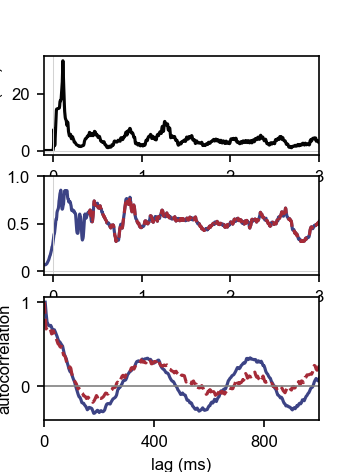

In [31]:
from scipy.signal import savgol_filter
# --- Fixed parameters ---
i = 5
print(fish_ids[i])
n = 5
dt = 1 / 300
t_onset = t_cont_onset_list[i][n]
color_vf = "#A62B38"
color_thrust = "#040404"
color_all_sigmal = "#3C4385"
factor_thrust = 1  # Adjust if needed

# --- Time series data ---
t = t_cont_list[i][n] - t_onset
vfish = vfish_cont_list[i][n]

vfish_smooth = savgol_filter(vfish, window_length=15, polyorder=3)

thrust = mean_thrust_cont_list[i][n] * factor_thrust * 1000

# --- ACF data --- from thrust
lags1 = acf_lags_list[i][n]
acf1 = acf_vals_list[i][n]
lags2 = acf_lags_no_onset_list[i][n]
acf2 = acf_vals_no_onset_list[i][n]

# --- ACF data --- from vf
lags3 = acf_lags_list_vfish[i][n]
acf3 = acf_vals_list_vfish[i][n]
lags4 = acf_lags_no_onset_list_vfish[i][n]
acf4 = acf_vals_no_onset_list_vfish[i][n]

default()
widget()
arial()

fig, axs = plt.subplots(
    3, 1,
    figsize=(6 / 2.54, 8 / 2.54),
    dpi=150,
    gridspec_kw={'height_ratios': [0.8, 0.8, 1]}
)

# --- Thrust time series ---
axs[0].plot(t, thrust, color=color_thrust)
axs[0].set_ylabel("thrust (nN)", color=color_thrust)
axs[0].tick_params(axis='y', colors=color_thrust)
axs[0].spines['left'].set_color(color_thrust)
axs[0].axhline(0, color='lightgray', linewidth=0.5)
axs[0].axvline(0, color='lightgray', linewidth=0.5)
axs[0].set_xlim(-0.1, 3)
axs[0].set_xlabel("time (s)")

# --- vfish time series ---
axs[1].plot(t, vfish_smooth, '-', color=color_all_sigmal)
axs[1].set_ylabel(r'$v_{\mathrm{f}}$ (cm/s)')
#axs[1].tick_params(axis='y', colors=color_vf)
#axs[1].spines['left'].set_color(color_vf)
axs[1].axhline(0, color='lightgray', linewidth=0.5)
axs[1].axvline(0, color='lightgray', linewidth=0.5)

axs[1].plot(t[t>0.4], vfish_smooth[t>0.4], '--', color=color_vf)

#axs[1].axvline(0.4, color='lightgray', linewidth=0.5)
axs[1].set_xlim(-0.1, 3)
axs[1].set_xlabel("time (s)")
axs[1].set_yticks([0.0, 5, 10], labels=[0, 0.5, 1.0])

# --- ACF plot of vfish ---
axs[2].plot(lags3, acf3, color=color_all_sigmal, label=r'ACF of $v_{\mathrm{f}}(t)$') 
axs[2].plot(lags4, acf4, '--', color=color_vf,  label=r'ACF of $v_{\mathrm{f}}(t > 0.4\,\mathrm{s})$') 
axs[2].axhline(0, color='gray', linewidth=0.8)
axs[2].set_xticks([0.0, 0.4, 0.8], labels=[0, 400, 800])
axs[2].set_yticks([0, 1], labels=[0, 1])
axs[2].set_xlabel("lag (ms)")
axs[2].set_ylabel("autocorrelation")
axs[2].set_xlim(0, 1)
#axs[2].legend()

fig.savefig(os.path.join(path_figures, "Fig_S9a_speed_modulation_ACF_example_1fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S9a_speed_modulation_ACF_example_1fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

## example 2

21_06Jun24_1


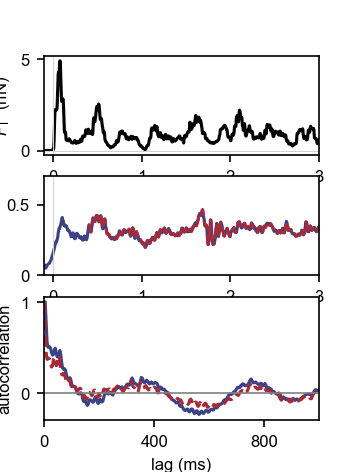

In [32]:
from scipy.signal import savgol_filter
# --- Fixed parameters ---
i = 14
print(fish_ids[i])
n = 3# 51
dt = 1 / 300
t_onset = t_cont_onset_list[i][n]
color_vf = "#A62B38"
color_thrust = "#040404"
color_all_sigmal = "#3C4385"
factor_thrust = 1  # Adjust if needed

# --- Time series data ---
t = t_cont_list[i][n] - t_onset
vfish = vfish_cont_list[i][n]

vfish_smooth = savgol_filter(vfish, window_length=15, polyorder=3)

thrust = mean_thrust_cont_list[i][n] * factor_thrust * 1000

# --- ACF data --- from thrust
lags1 = acf_lags_list[i][n]
acf1 = acf_vals_list[i][n]
lags2 = acf_lags_no_onset_list[i][n]
acf2 = acf_vals_no_onset_list[i][n]

# --- ACF data --- from vf
lags3 = acf_lags_list_vfish[i][n]
acf3 = acf_vals_list_vfish[i][n]
lags4 = acf_lags_no_onset_list_vfish[i][n]
acf4 = acf_vals_no_onset_list_vfish[i][n]

default()
widget()
arial()

fig, axs = plt.subplots(
    3, 1,
    figsize=(6 / 2.54, 8 / 2.54),
    dpi=150,
    gridspec_kw={'height_ratios': [0.8, 0.8, 1]}
)

# --- Thrust time series ---
axs[0].plot(t, thrust, color=color_thrust)
axs[0].set_ylabel(r'$F_{\mathrm{T}}$  (nN)', color=color_thrust)
axs[0].tick_params(axis='y', colors=color_thrust)
axs[0].spines['left'].set_color(color_thrust)
axs[0].axhline(0, color='lightgray', linewidth=0.5)
axs[0].axvline(0, color='lightgray', linewidth=0.5)
axs[0].set_xlim(-0.1, 3)
axs[0].set_xlabel("time (s)")

# --- vfish time series ---
axs[1].plot(t, vfish_smooth, '-', color=color_all_sigmal)
axs[1].set_ylabel(r'$v_{\mathrm{f}}$ (cm/s)')
#axs[1].tick_params(axis='y', colors=color_vf)
#axs[1].spines['left'].set_color(color_vf)
axs[1].axhline(0, color='lightgray', linewidth=0.5)
axs[1].axvline(0, color='lightgray', linewidth=0.5)

axs[1].plot(t[t>0.4], vfish_smooth[t>0.4], '--', color=color_vf)

#axs[1].axvline(0.4, color='lightgray', linewidth=0.5)
axs[1].set_xlim(-0.1, 3)
axs[1].set_xlabel("time (s)")
axs[1].set_ylim(0, 7)
axs[1].set_yticks([0.0, 5], labels=[0, 0.5])

# --- ACF plot of vfish ---
axs[2].plot(lags3, acf3, color=color_all_sigmal, label=r'ACF of $v_{\mathrm{f}}(t)$') 
axs[2].plot(lags4, acf4, '--', color=color_vf,  label=r'ACF of $v_{\mathrm{f}}(t > 0.4\,\mathrm{s})$') 
axs[2].axhline(0, color='gray', linewidth=0.8)
axs[2].set_xticks([0.0, 0.4, 0.8], labels=[0, 400, 800])
axs[2].set_yticks([0, 1], labels=[0, 1])
axs[2].set_xlabel("lag (ms)")
axs[2].set_ylabel("autocorrelation")
axs[2].set_xlim(0, 1)
#axs[2].legend()

fig.savefig(os.path.join(path_figures, "Fig_S9b_speed_modulation_ACF_example_2fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S9b_speed_modulation_ACF_example_2fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

In [ ]:
xx = [0.25, 0.5, 0.75, 1]
yc = [8, 2, 0.78, 0.4]
yb = [5, 1.7, 0.9, 0.55]

default()
arial()
widget()   
fig =plt.figure(figsize=(3,3),dpi=150)
plt.plot(xx, yc, '.-', color='blue')
plt.plot(xx, yb, '.-', color='red')
plt.ylabel('COT (cm/erg)')
plt.xlabel('fish lenght (cm)')
plt.show()